<a href="https://colab.research.google.com/github/hardikjain2005/-Predictive-Analytics-CA-3-Diabetes-Onset-Prediction-Using-Machine-Learning/blob/main/notebooks/Diabetes_Onset_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diabetes Onset Prediction Using Machine Learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hardikjain2005/-Predictive-Analytics-CA-3-Diabetes-Onset-Prediction-Using-Machine-Learning/blob/main/notebooks/Diabetes_Onset_Prediction.ipynb)

| | |
|---|---|
| **Student** | Hardik Jain |
| **Student ID** | 23070521056 |
| **Course** | Predictive Analytics |
| **Dataset** | Pima Indians Diabetes Dataset (768 patients, 8 diagnostic features) |

**Project objective.** Build an end-to-end predictive analytics model that estimates whether a patient is likely to have diabetes from routine diagnostic measurements (glucose, BMI, blood pressure, insulin, age, pregnancies, skin-fold thickness and diabetes pedigree function). The aim is to demonstrate how such a model could *support early screening* by flagging higher-risk individuals for follow-up testing.

> **Disclaimer.** This notebook is an academic machine-learning exercise. The model is **not** a medical diagnostic tool and must not be used to make clinical decisions.

## 0. Environment Setup (Local or Google Colab)

This notebook runs both **locally** (inside the cloned project folder) and in **Google Colab** (click the *Open in Colab* badge above, then **Runtime → Run all**).

The cell below:

1. checks whether the notebook is running inside the project folder;
2. if not (for example in Colab, where only this `.ipynb` file is opened), **clones the project from GitHub** so that the helper modules in `src/` are available;
3. installs any missing libraries (Colab already includes most of them).

The dataset itself is then loaded **directly from the GitHub repository** in Section 4.

In [46]:
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

GITHUB_REPO_URL = ("https://github.com/hardikjain2005/"
                   "-Predictive-Analytics-CA-3-Diabetes-Onset-Prediction-Using-Machine-Learning.git")
IN_COLAB = "google.colab" in sys.modules


def inside_project():
    return any((p / "src" / "preprocessing.py").exists() for p in [Path.cwd(), *Path.cwd().parents])


if not inside_project():
    # e.g. Google Colab: fetch the project (src/ modules, data/) from GitHub
    clone_dir = Path("/content/diabetes-onset-prediction") if IN_COLAB else Path.cwd() / "diabetes-onset-prediction"
    if not (clone_dir / "src" / "preprocessing.py").exists():
        print("Cloning project from GitHub ...")
        subprocess.run(["git", "clone", "--depth", "1", GITHUB_REPO_URL, str(clone_dir)], check=True)
    os.chdir(clone_dir)

# install any libraries that are not available yet (Colab already has most of them)
required = {"imblearn": "imbalanced-learn", "xgboost": "xgboost", "shap": "shap", "seaborn": "seaborn"}
missing = [pkg for module, pkg in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

print("Running in Google Colab:", IN_COLAB)
print("Working directory      :", Path.cwd().name)

Running in Google Colab: True
Working directory      : diabetes-onset-prediction


## 1. Problem Identification

**What is diabetes?** Diabetes mellitus is a chronic metabolic condition in which the body cannot properly regulate blood glucose, either because it produces too little insulin or because its cells respond poorly to insulin. Persistently high blood glucose can, over time, damage the heart, kidneys, eyes and nerves.

**Why early screening matters.** Type 2 diabetes often develops gradually and can remain unnoticed for years. Identifying people at higher risk early allows confirmatory testing, lifestyle changes and timely medical care, which can reduce the risk of complications.

**Why predictive analytics?** Hospitals routinely collect measurements such as plasma glucose and BMI. A predictive model can learn patterns linking these measurements to a known outcome and then produce a *risk estimate* for new patients. Such an estimate can help prioritise who should be referred for proper clinical testing.

**Prediction task.** This is a **supervised binary classification** problem.

| Role | Variables |
|---|---|
| **Input features (X)** | Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age |
| **Target (y)** | Outcome (0 = no diabetes, 1 = diabetes) |

**Formal statement.** Given a vector of diagnostic measurements $X = (x_1, \dots, x_8)$ for a patient, learn a function $f$ such that $f(X) \rightarrow \hat{y} \in \{0, 1\}$, together with an estimated probability $P(\text{Outcome} = 1 \mid X)$.

The model produced here is an **academic predictive screening model**. It identifies statistical associations in one historical dataset; it does not diagnose disease.

## 2. KDD / Predictive Analytics Workflow

The project follows the **Knowledge Discovery in Databases (KDD)** process, adapted to predictive modelling:

**Problem Definition → Data Selection → Data Understanding → Data Cleaning → Data Transformation → Exploratory Data Analysis → Model Construction → Model Evaluation → Interpretation → Knowledge / Insights**

Each numbered section of this notebook corresponds to one of these stages. The diagram below (drawn after the libraries are imported) summarises the flow.

## 3. Import Libraries and Configuration

* **pandas / numpy** – data handling
* **matplotlib / seaborn** – visualisation
* **scikit-learn** – splitting, imputation, scaling, models and metrics
* **imbalanced-learn** – SMOTE and an imbalance-aware pipeline
* **xgboost** – gradient-boosted trees
* **shap** – model interpretation

The project's reusable helper functions live in `src/` (`preprocessing.py`, `models.py`, `evaluation.py`). The cell below locates the project root so the notebook works whether it is started from the project folder or from `notebooks/`. A single `RANDOM_STATE = 42` is used everywhere for reproducibility.

In [47]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyBboxPatch

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.inspection import permutation_importance
from imblearn.over_sampling import SMOTE
import xgboost
import sklearn
import imblearn

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# ---- locate the project root (folder that contains src/preprocessing.py) ----
PROJECT_ROOT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "src" / "preprocessing.py").exists():
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise RuntimeError("Run this notebook from inside the diabetes-onset-prediction project folder.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from preprocessing import (FEATURES, TARGET, COLUMNS, ZERO_AS_MISSING, RANDOM_STATE,
                           load_data, GITHUB_DATA_URL, count_invalid_zeros, replace_invalid_zeros,
                           split_data, build_preprocessor)
from models import get_classifiers, build_pipeline, get_models, train_models, cross_validate_models
from evaluation import (evaluate_models, print_classification_reports, plot_confusion_matrices,
                        plot_roc_curves, best_per_metric)

DATA_PATH = PROJECT_ROOT / "data" / "pima-indians-diabetes.csv"
RESULTS_DIR = PROJECT_ROOT / "results"
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- plotting configuration ----
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13, "axes.labelsize": 11,
                     "axes.titleweight": "bold"})
OUTCOME_LABELS = {0: "No Diabetes", 1: "Diabetes"}
PALETTE = {"No Diabetes": "#4C72B0", "Diabetes": "#DD8452"}
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)


def save_fig(fig, name):
    """Save a figure to results/figures/ at a readable resolution."""
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")


print("Project root :", PROJECT_ROOT.name)
print("Random state :", RANDOM_STATE)
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | "
      f"imbalanced-learn {imblearn.__version__} | xgboost {xgboost.__version__}")

Project root : diabetes-onset-prediction
Random state : 42
pandas 2.2.3 | numpy 2.1.3 | scikit-learn 1.6.1 | imbalanced-learn 0.14.2 | xgboost 3.4.1


### KDD workflow diagram

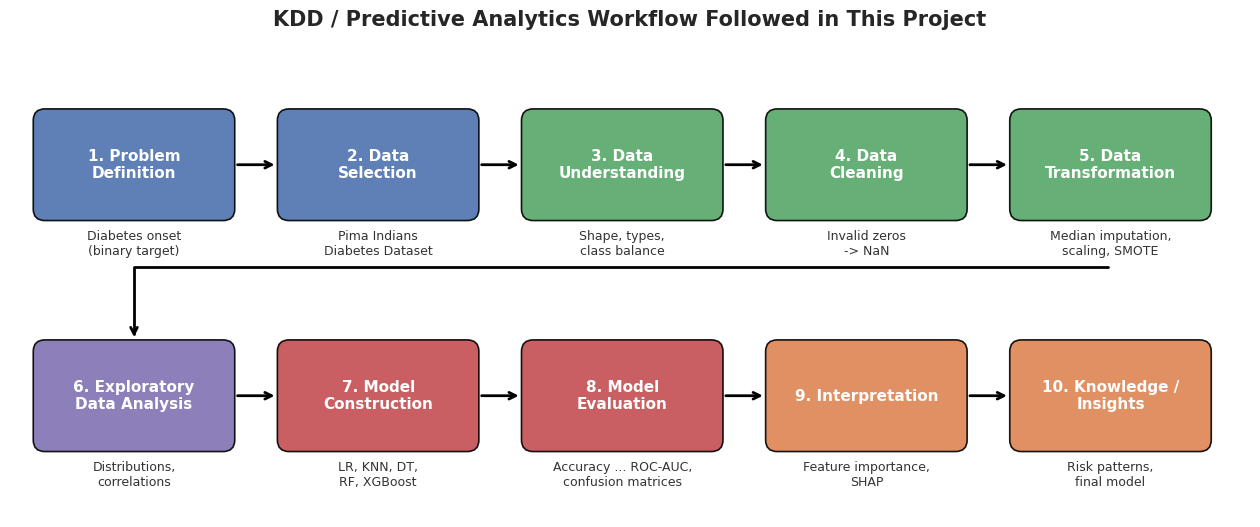

In [48]:
stages = ["Problem\nDefinition", "Data\nSelection", "Data\nUnderstanding", "Data\nCleaning",
          "Data\nTransformation", "Exploratory\nData Analysis", "Model\nConstruction",
          "Model\nEvaluation", "Interpretation", "Knowledge /\nInsights"]
details = ["Diabetes onset\n(binary target)", "Pima Indians\nDiabetes Dataset", "Shape, types,\nclass balance",
           "Invalid zeros\n-> NaN", "Median imputation,\nscaling, SMOTE", "Distributions,\ncorrelations",
           "LR, KNN, DT,\nRF, XGBoost", "Accuracy ... ROC-AUC,\nconfusion matrices",
           "Feature importance,\nSHAP", "Risk patterns,\nfinal model"]
colors = ["#4C72B0"] * 2 + ["#55A868"] * 3 + ["#8172B3"] + ["#C44E52"] * 2 + ["#DD8452"] * 2

fig, ax = plt.subplots(figsize=(16, 6.2))
ax.set_xlim(0, 16); ax.set_ylim(0, 6.2); ax.axis("off")
w, h = 2.5, 1.35
xs = [0.35 + i * 3.15 for i in range(5)]
positions = [(x, 3.9) for x in xs] + [(x, 0.9) for x in xs]
for i, ((x, y), stage, detail, c) in enumerate(zip(positions, stages, details, colors)):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05,rounding_size=0.15",
                                facecolor=c, edgecolor="black", linewidth=1.2, alpha=0.9))
    ax.text(x + w / 2, y + h / 2, f"{i + 1}. {stage}", ha="center", va="center",
            color="white", fontsize=11, fontweight="bold")
    ax.text(x + w / 2, y - 0.35, detail, ha="center", va="center", fontsize=9, color="#333333")
    if i in (0, 1, 2, 3, 5, 6, 7, 8):
        nx, ny = positions[i + 1]
        ax.annotate("", xy=(nx - 0.05, ny + h / 2), xytext=(x + w + 0.05, y + h / 2),
                    arrowprops=dict(arrowstyle="->", lw=2, color="black"))
# connector from stage 5 (end of row 1) to stage 6 (start of row 2)
x5, y5 = positions[4]; x6, y6 = positions[5]
ax.annotate("", xy=(x6 + w / 2, y6 + h + 0.05),
            xytext=(x5 + w / 2, y5 - 0.65),
            arrowprops=dict(arrowstyle="->", lw=2, color="black",
                            connectionstyle="angle,angleA=180,angleB=90,rad=0"))
ax.set_title("KDD / Predictive Analytics Workflow Followed in This Project", fontsize=15, pad=10)
save_fig(fig, "01_kdd_workflow.png")
plt.show()

## 4. Load the Dataset (Data Selection)

The dataset is the **Pima Indians Diabetes Dataset**, originally from the US National Institute of Diabetes and Digestive and Kidney Diseases and distributed through the UCI Machine Learning Repository. All patients are females of Pima Indian heritage aged at least 21 years.

The dataset (originally from `https://github.com/jbrownlee/Datasets`, stored with column headers) is part of this project's GitHub repository:

`https://raw.githubusercontent.com/hardikjain2005/-Predictive-Analytics-CA-3-Diabetes-Onset-Prediction-Using-Machine-Learning/main/data/pima-indians-diabetes.csv`

* In **Google Colab** (or whenever the local file is missing) it is **read directly from this GitHub URL**.
* When running locally inside the project, the identical copy in `data/pima-indians-diabetes.csv` is used.

In [49]:
if IN_COLAB or not DATA_PATH.exists():
    try:
        df_raw = load_data(GITHUB_DATA_URL)          # read directly from GitHub
        DATA_SOURCE = "GitHub - " + GITHUB_DATA_URL
    except Exception as exc:
        raise ConnectionError(
            f"Could not read the dataset from GitHub ({exc}).\n"
            "Check the internet connection, or place the CSV at data/pima-indians-diabetes.csv."
        )
else:
    df_raw = load_data(DATA_PATH)                    # local copy inside the project
    DATA_SOURCE = "local file - " + str(DATA_PATH.relative_to(PROJECT_ROOT))

print("Loaded from:", DATA_SOURCE)
print("Shape :", df_raw.shape, "(rows, columns)")
print("Columns:", list(df_raw.columns))

Loaded from: GitHub - https://raw.githubusercontent.com/hardikjain2005/-Predictive-Analytics-CA-3-Diabetes-Onset-Prediction-Using-Machine-Learning/main/data/pima-indians-diabetes.csv
Shape : (768, 9) (rows, columns)
Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [50]:
print("First 5 rows")
df_raw.head()

First 5 rows


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [51]:
print("Last 5 rows")
df_raw.tail()

Last 5 rows


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


## 5. Data Understanding

We now inspect the structure of the data: data types, summary statistics, missing values, duplicates, the number of unique values and the class distribution.

In [52]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [53]:
print("Data types:")
print(df_raw.dtypes)

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


In [54]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


In [55]:
print("Missing values (NaN) per column:")
print(df_raw.isna().sum())
print("\nDuplicate rows:", df_raw.duplicated().sum())
print("\nUnique values per column:")
print(df_raw.nunique())

Missing values (NaN) per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate rows: 0

Unique values per column:
Pregnancies                  17
Glucose                     136
BloodPressure                47
SkinThickness                51
Insulin                     186
BMI                         248
DiabetesPedigreeFunction    517
Age                          52
Outcome                       2
dtype: int64


In [56]:
class_counts = df_raw[TARGET].value_counts().sort_index()
class_table = pd.DataFrame({"Class": [OUTCOME_LABELS[i] for i in class_counts.index],
                            "Count": class_counts.values,
                            "Percentage (%)": (class_counts.values / len(df_raw) * 100).round(2)},
                           index=class_counts.index)
class_table

,Class,Count,Percentage (%)
Outcome,,,
0,No Diabetes,500,65.1
1,Diabetes,268,34.9


**Observations**

* The dataset has **768 rows and 9 columns**; all columns are numeric (`int64` or `float64`), so no categorical encoding is required.
* `df.info()` reports **no NaN values** and there are **no duplicate rows**. However, this is misleading, as the summary statistics show.
* `describe()` shows a **minimum of 0** for Glucose, BloodPressure, SkinThickness, Insulin and BMI. A living person cannot have zero blood glucose, zero blood pressure or a BMI of zero, so these zeros are **placeholders for missing measurements**, not real values.
* `Outcome` has only two unique values, confirming a binary classification target.
* The classes are **imbalanced**: about **65 % non-diabetic (500)** versus **35 % diabetic (268)**. A model that always predicts "no diabetes" would already reach about 65 % accuracy, so accuracy alone is not a sufficient metric.
* Insulin has a very large spread (max 846 vs. median 30.5), indicating strong right skew and outliers.

## 6. Data Quality Check (Data Cleaning)

Zero is treated as **invalid / missing** in five columns:

| Column | Why 0 is invalid |
|---|---|
| Glucose | plasma glucose cannot be 0 in a living patient |
| BloodPressure | diastolic blood pressure cannot be 0 |
| SkinThickness | triceps skin-fold thickness cannot be 0 mm |
| Insulin | 2-hour serum insulin of exactly 0 indicates "not measured" |
| BMI | body-mass index cannot be 0 |

Zeros are **kept** in `Pregnancies` (0 pregnancies is a valid value) and `Outcome` (0 is the negative class). `Age` and `DiabetesPedigreeFunction` contain no zeros.

In [57]:
zero_table = count_invalid_zeros(df_raw)
zero_table

,Invalid zeros,Percentage (%)
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43


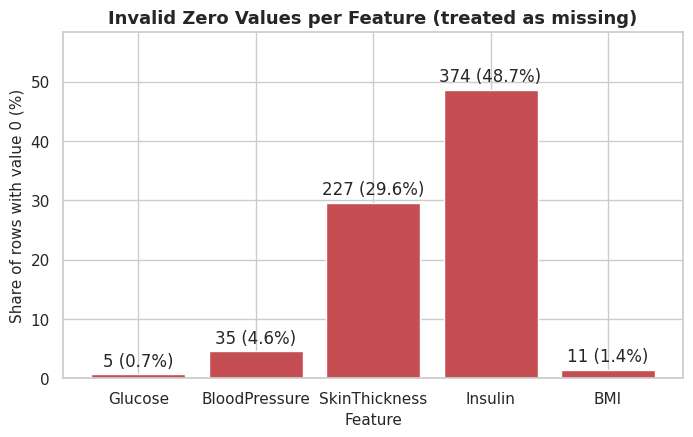

In [58]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(zero_table.index, zero_table["Percentage (%)"], color="#C44E52")
ax.bar_label(bars, labels=[f"{n} ({p:.1f}%)" for n, p in zip(zero_table["Invalid zeros"],
                                                            zero_table["Percentage (%)"])], padding=3)
ax.set_title("Invalid Zero Values per Feature (treated as missing)")
ax.set_xlabel("Feature")
ax.set_ylabel("Share of rows with value 0 (%)")
ax.set_ylim(0, zero_table["Percentage (%)"].max() * 1.2)
save_fig(fig, "02_invalid_zeros.png")
plt.show()

**Replacing invalid zeros with NaN.** Replacing a 0 with `NaN` is a fixed, row-by-row rule: it does not compute any statistic from the data, so doing it on the full dataset **cannot leak** information from the test set into training. The *imputation* of these NaNs (with a median) **does** learn a statistic, so it is deliberately postponed until after the train/test split (Section 8).

In [59]:
df = replace_invalid_zeros(df_raw)

missing = pd.DataFrame({"Missing after replacement": df.isna().sum(),
                        "Percentage (%)": (df.isna().mean() * 100).round(2)})
missing

,Missing after replacement,Percentage (%)
Pregnancies,0,0.00
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43
DiabetesPedigreeFunction,0,0.00
Age,0,0.00
Outcome,0,0.00


Insulin (about 49 % missing) and SkinThickness (about 30 % missing) have substantial missingness. Dropping these rows would discard roughly half of the dataset, so imputation is preferred. The **median** is used instead of the mean because Insulin and SkinThickness are right-skewed and the median is robust to outliers.

## 7. Exploratory Data Analysis (EDA)

EDA is performed on the cleaned data (zeros replaced with NaN, missing values simply ignored by each plot). EDA is descriptive only: no parameter learned here is used by the models, so it does not introduce leakage. A readable `Diagnosis` label is added for plotting.

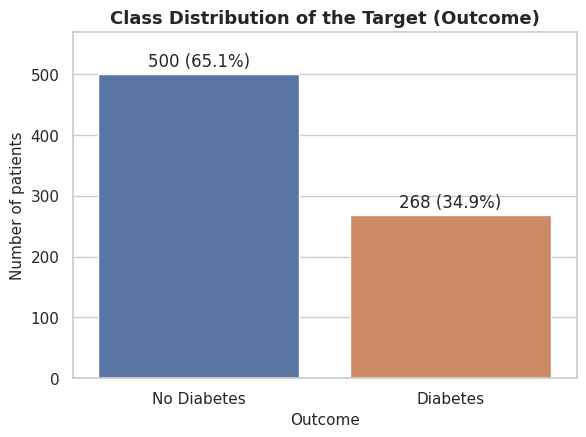

In [60]:
eda = df.copy()
eda["Diagnosis"] = eda[TARGET].map(OUTCOME_LABELS)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
order = ["No Diabetes", "Diabetes"]
sns.countplot(data=eda, x="Diagnosis", hue="Diagnosis", order=order, palette=PALETTE, legend=False, ax=ax)
for container in ax.containers:
    ax.bar_label(container, labels=[f"{int(v)} ({v / len(eda) * 100:.1f}%)" for v in container.datavalues],
                 padding=3)
ax.set_title("Class Distribution of the Target (Outcome)")
ax.set_xlabel("Outcome")
ax.set_ylabel("Number of patients")
ax.set_ylim(0, 570)
save_fig(fig, "03_outcome_distribution.png")
plt.show()

### 7.1 Distribution of each feature

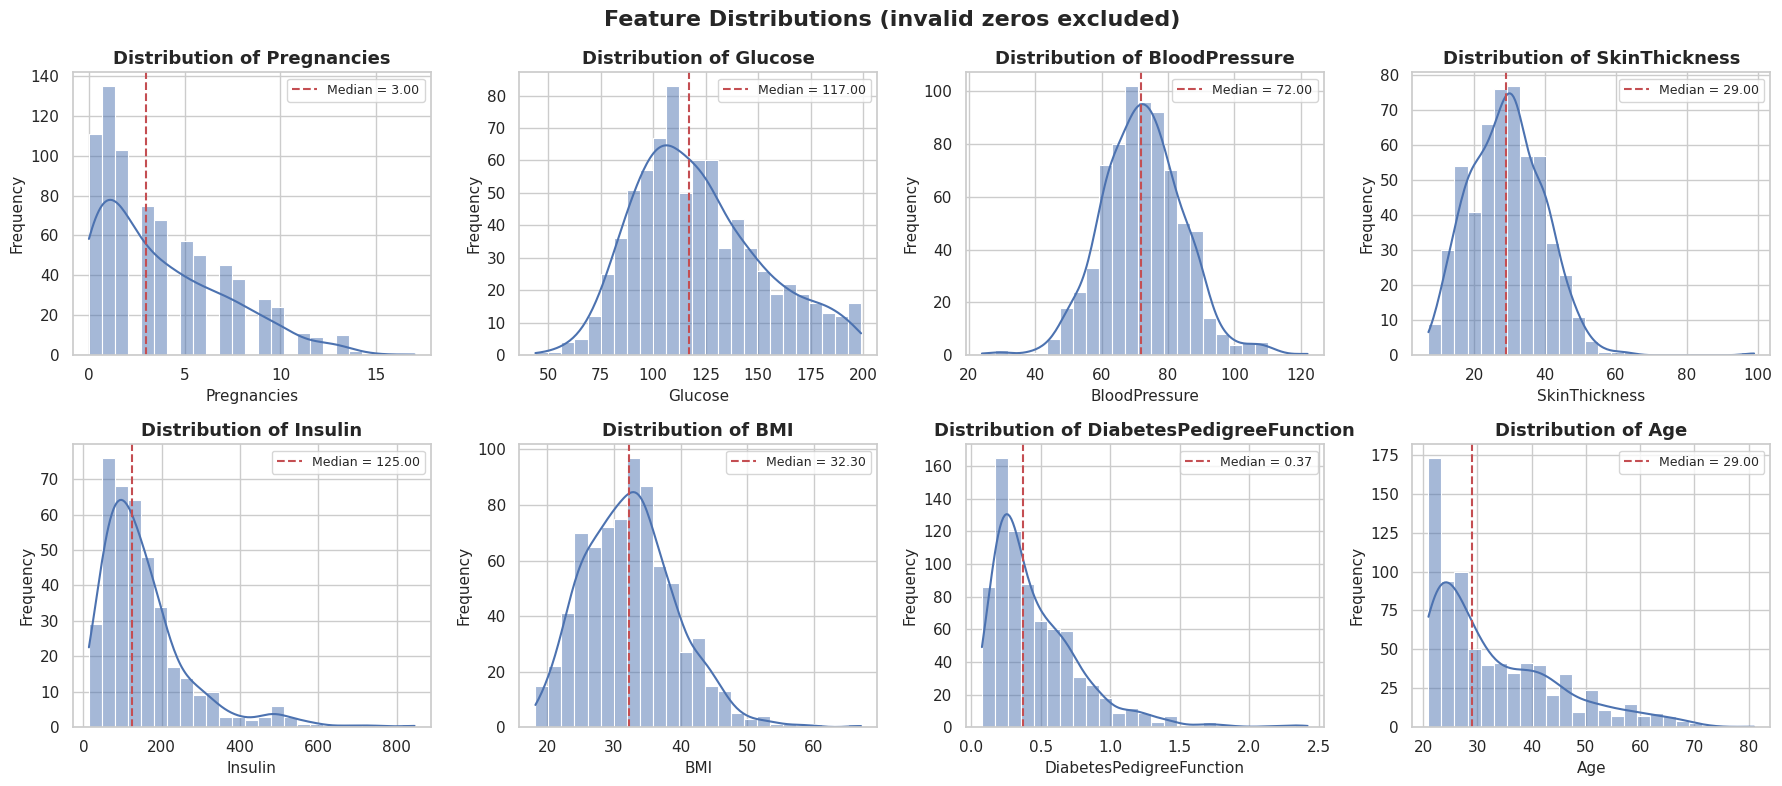

In [61]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(eda[col].dropna(), kde=True, bins=25, color="#4C72B0", ax=ax)
    ax.axvline(eda[col].median(), color="#C44E52", linestyle="--", label=f"Median = {eda[col].median():.2f}")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=9)
fig.suptitle("Feature Distributions (invalid zeros excluded)", fontsize=16, fontweight="bold")
fig.tight_layout()
save_fig(fig, "04_feature_distributions.png")
plt.show()

### 7.2 Key features by Outcome

Overlaid density histograms compare the distribution of a feature for diabetic and non-diabetic patients. `common_norm=False` normalises each class separately so the shapes are comparable despite class imbalance.

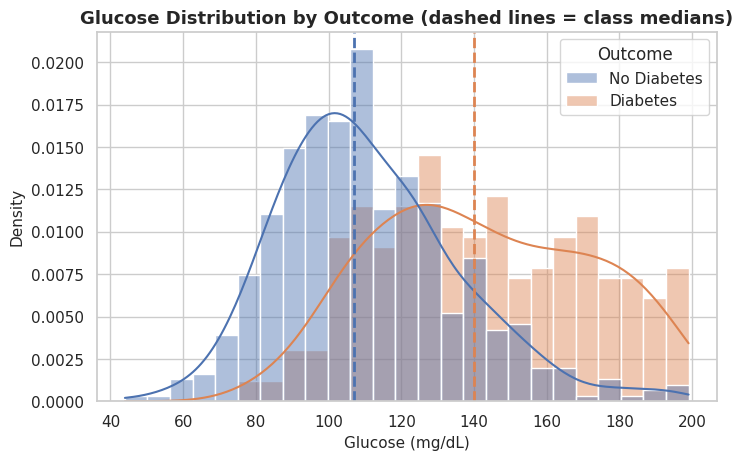

Diagnosis
No Diabetes    107.0
Diabetes       140.0


In [62]:
def plot_by_outcome(feature, filename, unit=""):
    fig, ax = plt.subplots(figsize=(8, 4.8))
    sns.histplot(data=eda, x=feature, hue="Diagnosis", hue_order=order, palette=PALETTE,
                 kde=True, stat="density", common_norm=False, bins=25, alpha=0.45, ax=ax)
    for label in order:
        med = eda.loc[eda["Diagnosis"] == label, feature].median()
        ax.axvline(med, color=PALETTE[label], linestyle="--", linewidth=2)
    ax.set_title(f"{feature} Distribution by Outcome (dashed lines = class medians)")
    ax.set_xlabel(f"{feature}{unit}")
    ax.set_ylabel("Density")
    ax.get_legend().set_title("Outcome")
    save_fig(fig, filename)
    plt.show()
    print(eda.groupby("Diagnosis")[feature].median().reindex(order).rename(f"Median {feature}").to_string())

plot_by_outcome("Glucose", "05_glucose_by_outcome.png", " (mg/dL)")

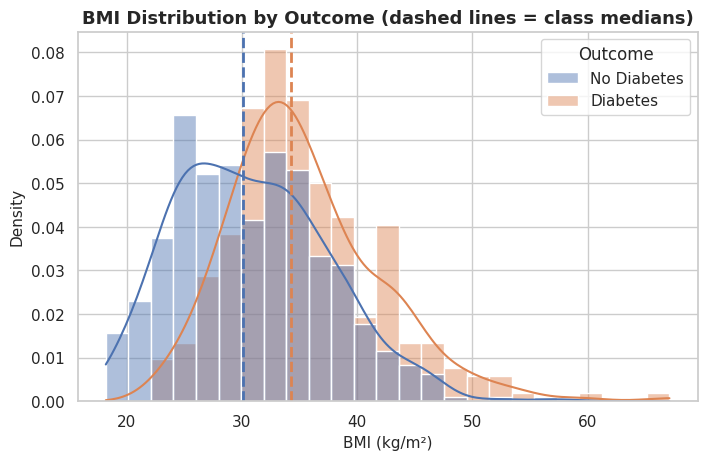

Diagnosis
No Diabetes    30.1
Diabetes       34.3


In [63]:
plot_by_outcome("BMI", "06_bmi_by_outcome.png", " (kg/m²)")

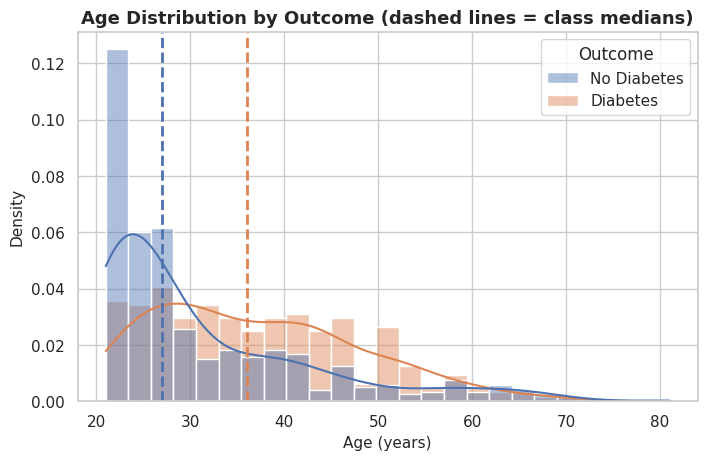

Diagnosis
No Diabetes    27.0
Diabetes       36.0


In [64]:
plot_by_outcome("Age", "07_age_by_outcome.png", " (years)")

### 7.3 Boxplots of all features by Outcome

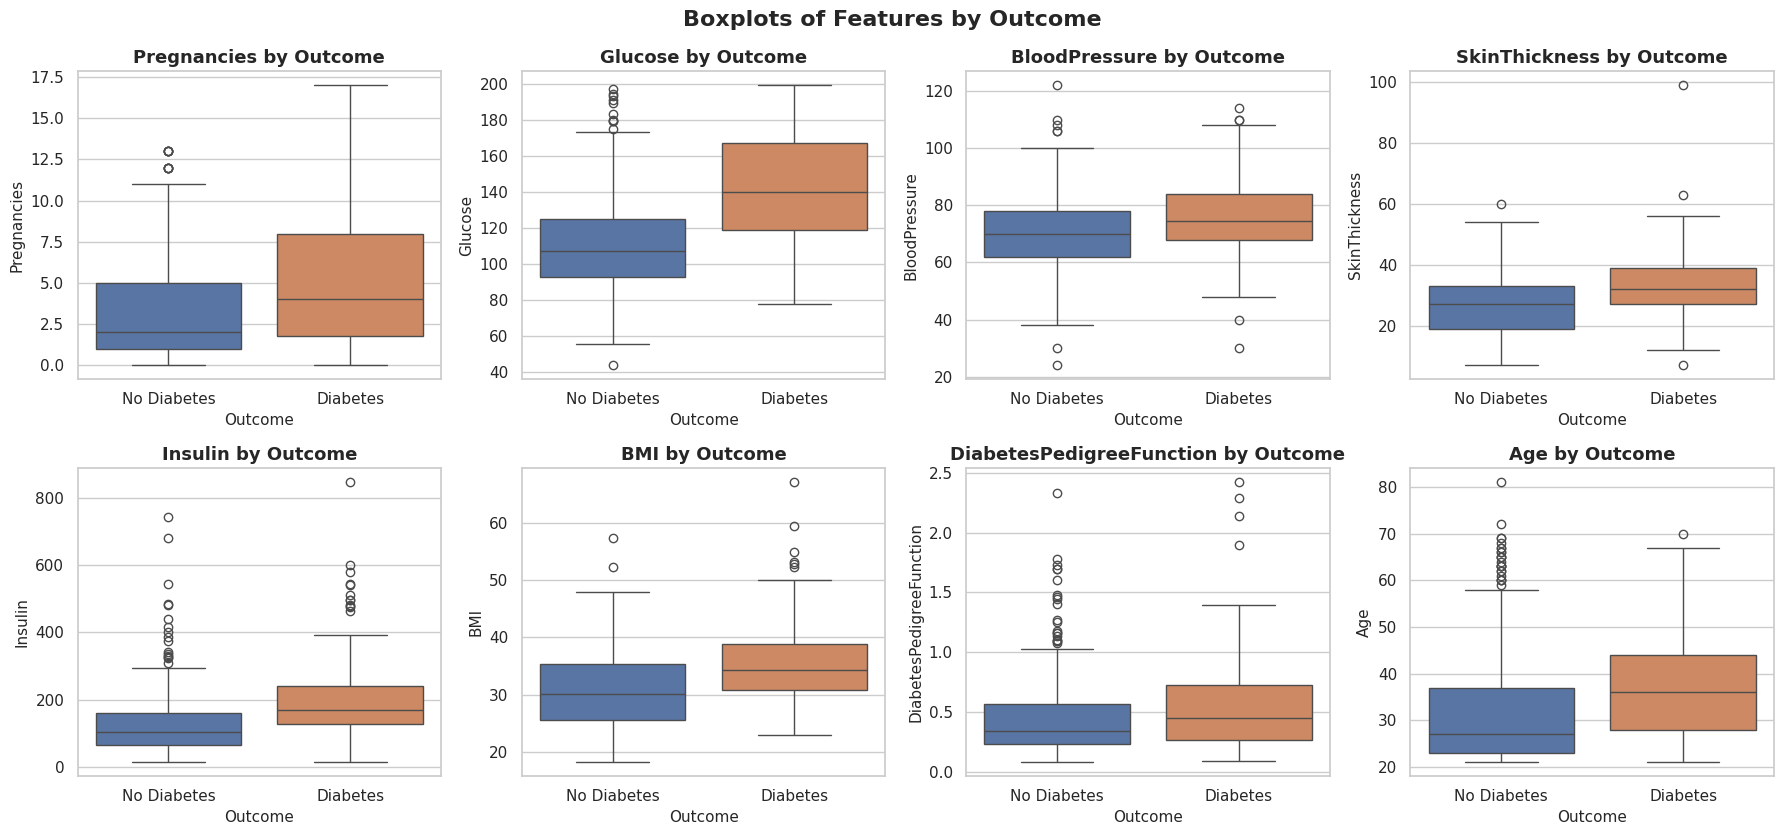

Diagnosis,No Diabetes,Diabetes
Pregnancies,2.00,4.00
Glucose,107.00,140.00
BloodPressure,70.00,74.50
SkinThickness,27.00,32.00
Insulin,102.50,169.50
BMI,30.10,34.30
DiabetesPedigreeFunction,0.34,0.45
Age,27.00,36.00


In [65]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=eda, x="Diagnosis", y=col, hue="Diagnosis", order=order, hue_order=order,
                palette=PALETTE, legend=False, ax=ax)
    ax.set_title(f"{col} by Outcome")
    ax.set_xlabel("Outcome")
    ax.set_ylabel(col)
fig.suptitle("Boxplots of Features by Outcome", fontsize=16, fontweight="bold")
fig.tight_layout()
save_fig(fig, "08_boxplots_by_outcome.png")
plt.show()

eda.groupby("Diagnosis")[FEATURES].median().reindex(order).T.round(2)

### 7.4 Correlation heatmap

Pearson correlations are computed on pairwise-complete observations (NaNs ignored). Only the lower triangle is shown because the matrix is symmetric.

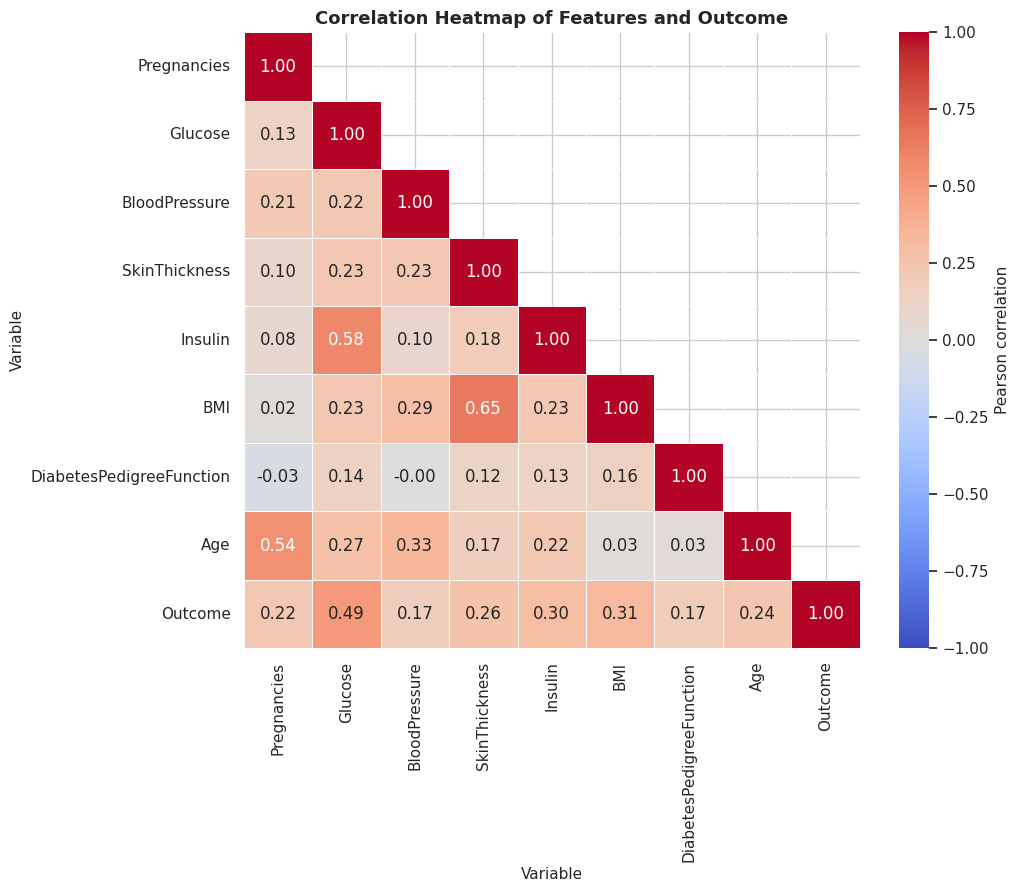

Correlation of each feature with Outcome:
Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171


In [66]:
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation Heatmap of Features and Outcome")
ax.set_xlabel("Variable")
ax.set_ylabel("Variable")
save_fig(fig, "09_correlation_heatmap.png")
plt.show()

print("Correlation of each feature with Outcome:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_string())

### 7.5 Pairwise relationships of selected features

A full 8×8 pairplot is cluttered, so only the four features most correlated with the outcome are shown. Only the 392 patients with all four values recorded are plotted, because Insulin is missing for many patients.

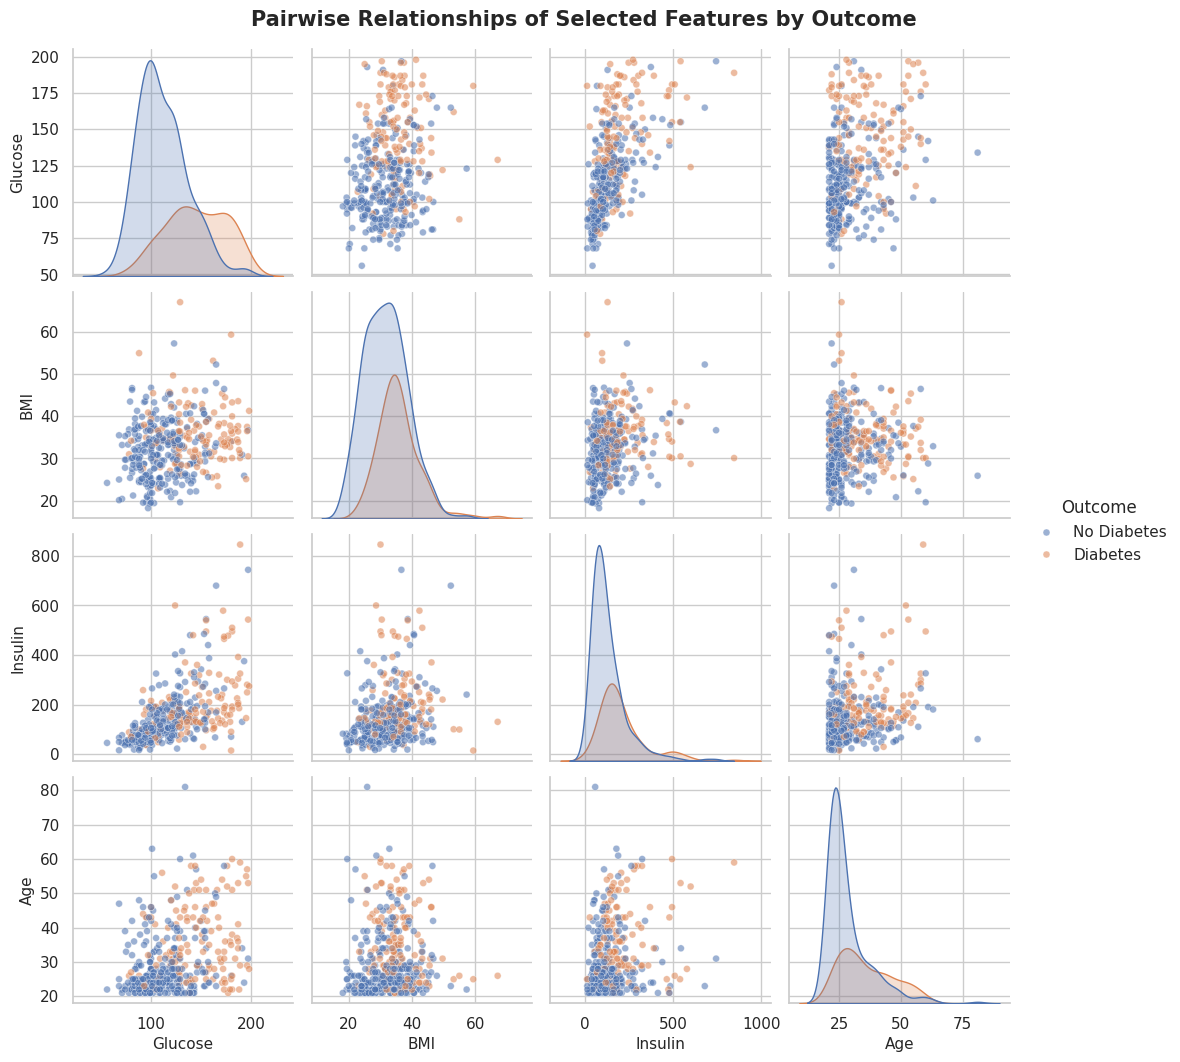

In [67]:
pair_cols = ["Glucose", "BMI", "Insulin", "Age"]
g = sns.pairplot(eda[pair_cols + ["Diagnosis"]].dropna(), hue="Diagnosis", hue_order=order,
                 palette=PALETTE, diag_kind="kde", plot_kws={"alpha": 0.55, "s": 25}, height=2.6)
g.figure.suptitle("Pairwise Relationships of Selected Features by Outcome", y=1.02,
                  fontsize=15, fontweight="bold")
g._legend.set_title("Outcome")
g.savefig(FIG_DIR / "10_pairplot_selected_features.png", dpi=150, bbox_inches="tight")
plt.show()

### EDA interpretation

* **Glucose** shows the clearest separation between the classes. The median glucose of diabetic patients (140 mg/dL) is much higher than that of non-diabetic patients (107 mg/dL), and Glucose has the strongest correlation with Outcome (about 0.49). This suggests glucose will be an important predictor.
* **BMI** is higher on average in the diabetic group (median 34.3 vs. 30.1), with a moderate correlation of about 0.31.
* **Age** distributions differ: non-diabetic patients are concentrated in their 20s (median 27), while diabetic patients are spread more widely toward older ages (median 36).
* **Insulin** and **SkinThickness** are also higher in the diabetic group, but they have the most missing data, so their patterns should be interpreted with caution.
* **Feature-feature correlations**: SkinThickness–BMI (about 0.65), Glucose–Insulin (about 0.58) and Pregnancies–Age (about 0.54) are the strongest. These are moderate rather than extreme, so multicollinearity is not severe enough to require removing features.
* **Skewness and outliers**: Insulin, DiabetesPedigreeFunction, Age and Pregnancies are right-skewed. Median imputation and standard scaling are suitable for this.
* Every feature shows *overlap* between the two classes, so no single measurement separates them perfectly. A multivariate model is needed.

These are **associations** observed in this sample. They do not show that any measurement *causes* diabetes.

## 8. Data Preprocessing (Data Transformation)

**Steps**

1. Invalid zeros have already been replaced with NaN (Section 6).
2. Separate features `X` from the target `y`.
3. **Split into training (80 %) and test (20 %) sets before fitting anything**, using `stratify=y` so both sets keep the 65/35 class ratio.
4. Fit a **median imputer** on the training set only and use it to fill NaNs in both sets.
5. Fit a **StandardScaler** on the training set only and use it to transform both sets.

**Why the test set must not influence preprocessing.** The test set represents future, unseen patients. If imputation medians or scaling means were computed on the full dataset, information about the test patients would be built into the training process. That is **data leakage**, and it makes evaluation scores optimistically biased. Fitting every transformer on the training data only keeps the test evaluation honest.

In [68]:
X_train, X_test, y_train, y_test = split_data(df, test_size=0.2, random_state=RANDOM_STATE)
# equivalent to: train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

split_summary = pd.DataFrame({
    "Rows": [len(X_train), len(X_test)],
    "No Diabetes (0)": [(y_train == 0).sum(), (y_test == 0).sum()],
    "Diabetes (1)": [(y_train == 1).sum(), (y_test == 1).sum()],
    "Diabetes share (%)": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
}, index=["Training set", "Test set"])
split_summary

,Rows,No Diabetes (0),Diabetes (1),Diabetes share (%)
Training set,614,400,214,34.85
Test set,154,100,54,35.06


In [69]:
preprocessor = build_preprocessor(scale=True)          # median imputer + StandardScaler (unfitted)
X_train_prep = preprocessor.fit_transform(X_train)     # FIT on training data only
X_test_prep = preprocessor.transform(X_test)           # only TRANSFORM the test data

learned = pd.DataFrame({
    "Imputation median (train)": preprocessor.named_steps["imputer"].statistics_,
    "Scaler mean (train)": preprocessor.named_steps["scaler"].mean_,
    "Scaler std (train)": preprocessor.named_steps["scaler"].scale_,
}, index=FEATURES).round(3)
print("Missing values after preprocessing -> train:", np.isnan(X_train_prep).sum(),
      "| test:", np.isnan(X_test_prep).sum())
learned

Missing values after preprocessing -> train: 0 | test: 0


,Imputation median (train),Scaler mean (train),Scaler std (train)
Pregnancies,3.000,3.819,3.311
Glucose,117.000,121.671,29.979
BloodPressure,72.000,72.140,12.265
SkinThickness,29.000,29.042,8.885
Insulin,125.000,137.705,78.701
BMI,32.400,32.448,6.819
DiabetesPedigreeFunction,0.382,0.477,0.330
Age,29.000,33.366,11.824


The table shows the statistics **learned from the 614 training rows only**. The same medians, means and standard deviations are then applied to the 154 test rows. After preprocessing there are no missing values left.

## 9. Handling Class Imbalance

**Why imbalance matters.** With 65 % negatives, a classifier can reach high accuracy by favouring the majority class while missing many diabetic patients. In a screening setting, missed positive cases (false negatives) are especially undesirable.

**SMOTE (Synthetic Minority Over-sampling Technique)** creates new synthetic minority-class examples by interpolating between a minority sample and one of its nearest minority-class neighbours. This balances the training data without simply duplicating rows.

**Rules followed**

* SMOTE is applied **only to the training data**, after the split. Applying it before the split would place synthetic copies derived from test patients into training (leakage) and would distort the test set's real class ratio.
* SMOTE is applied **after imputation and scaling**, because SMOTE uses distances and cannot handle NaNs.
* In the modelling pipelines (Section 10), SMOTE is placed *inside* an `imblearn` pipeline, so during cross-validation it is applied to each training fold only, never to the validation fold.

The cell below demonstrates the effect of SMOTE on the preprocessed training set.

In [70]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train_prep, y_train)

before = y_train.value_counts().sort_index()
after = pd.Series(y_train_smote).value_counts().sort_index()
smote_table = pd.DataFrame({"Before SMOTE": before, "After SMOTE": after})
smote_table.index = [OUTCOME_LABELS[i] for i in smote_table.index]
print("Test set is NOT resampled:", y_test.value_counts().sort_index().to_dict())
smote_table

Test set is NOT resampled: {0: 100, 1: 54}


,Before SMOTE,After SMOTE
No Diabetes,400,400
Diabetes,214,400


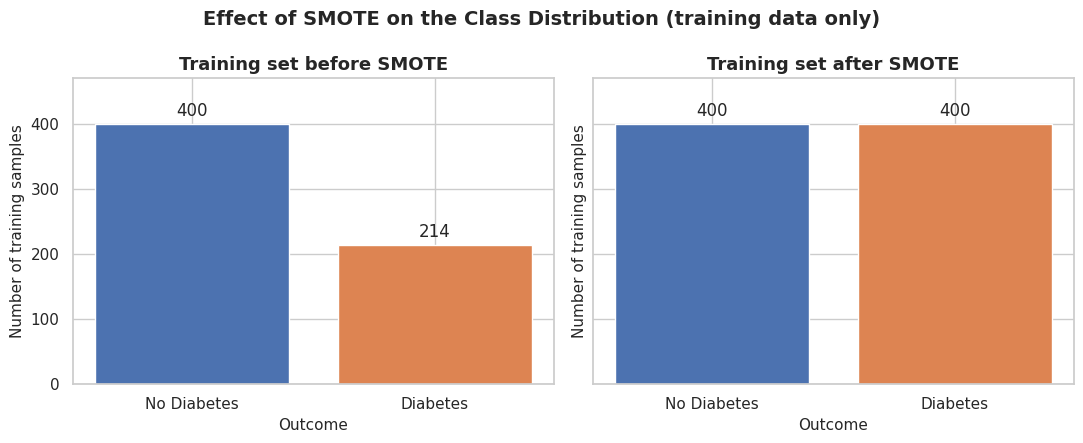

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (title, counts) in zip(axes, [("Training set before SMOTE", before),
                                       ("Training set after SMOTE", after)]):
    labels = [OUTCOME_LABELS[i] for i in counts.index]
    bars = ax.bar(labels, counts.values, color=[PALETTE[l] for l in labels])
    ax.bar_label(bars, padding=3)
    ax.set_title(title)
    ax.set_xlabel("Outcome")
    ax.set_ylabel("Number of training samples")
axes[0].set_ylim(0, 470)
fig.suptitle("Effect of SMOTE on the Class Distribution (training data only)", fontsize=14,
             fontweight="bold")
fig.tight_layout()
save_fig(fig, "11_smote_class_distribution.png")
plt.show()

**Alternative: `class_weight="balanced"`.** Instead of creating synthetic rows, some algorithms (e.g. Logistic Regression, Decision Tree, Random Forest) can give larger weight to errors on the minority class. As a quick check, we compare three ways of handling imbalance for Logistic Regression using **5-fold stratified cross-validation on the training set only**:

1. no imbalance handling,
2. `class_weight="balanced"`,
3. SMOTE inside the pipeline.

Using both SMOTE *and* class weights together would compensate for the imbalance twice, so the main experiments use SMOTE alone.

In [72]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
variants = {
    "No imbalance handling": build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                                            use_smote=False),
    "class_weight='balanced'": build_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced",
                                                                 random_state=RANDOM_STATE), use_smote=False),
    "SMOTE": build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), use_smote=True),
}
rows = []
for name, pipe in variants.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "recall", "f1", "roc_auc"])
    rows.append({"Strategy": name, "CV Accuracy": s["test_accuracy"].mean(), "CV Recall": s["test_recall"].mean(),
                 "CV F1": s["test_f1"].mean(), "CV ROC-AUC": s["test_roc_auc"].mean()})
imbalance_comparison = pd.DataFrame(rows).set_index("Strategy").round(4)
imbalance_comparison

,CV Accuracy,CV Recall,CV F1,CV ROC-AUC
Strategy,,,,
No imbalance handling,0.7882,0.5748,0.6545,0.8434
class_weight='balanced',0.7622,0.7010,0.6724,0.8444
SMOTE,0.7720,0.7244,0.6885,0.8427


Without imbalance handling, Logistic Regression keeps slightly higher accuracy but its **recall drops sharply**, so it misses many more diabetic patients. Both SMOTE and `class_weight="balanced"` raise recall substantially for a small cost in accuracy, and ROC-AUC stays almost unchanged. This is expected: ROC-AUC measures *ranking* quality, while imbalance handling mainly shifts the decision boundary toward the minority class. Both approaches give similar results here; SMOTE is used for all five models because it works the same way for every algorithm, including KNN, which has no `class_weight` option.

## 10. Model Development (Model Selection)

Five classifiers of increasing complexity are compared:

| Model | Idea | Needs scaling? | Settings used |
|---|---|---|---|
| **Logistic Regression** | Linear model of the log-odds; interpretable baseline | Yes | `max_iter=1000` |
| **K-Nearest Neighbors** | Majority vote of the *k* most similar patients | Yes (distance-based) | `n_neighbors=15` |
| **Decision Tree** | A sequence of if/else splits on features | No | `max_depth=5`, `min_samples_leaf=5` (limits overfitting) |
| **Random Forest** | Many decorrelated trees, averaged (bagging) | No | `n_estimators=300`, `min_samples_leaf=2` |
| **XGBoost** | Trees built sequentially to correct earlier errors (boosting) | No | `n_estimators=200`, `max_depth=3`, `learning_rate=0.05`, `subsample=0.8`, `colsample_bytree=0.8` |

These are reasonable, conservative settings rather than the result of an exhaustive hyperparameter search. All models use `random_state=42` where supported.

**A single consistent pipeline for every model**

```
SimpleImputer(median) → StandardScaler → SMOTE → Classifier
```

Scaling is essential for Logistic Regression and KNN. Tree-based models do not need it, because a monotonic rescaling does not change which splits are possible. Scaling is still kept for them because it (a) keeps one consistent methodology and (b) puts features on comparable scales for SMOTE's nearest-neighbour search. Because everything is inside one `imblearn` pipeline, calling `.fit()` learns imputation, scaling and SMOTE from the training data only.

In [73]:
models = get_models(random_state=RANDOM_STATE)
models["Random Forest"]   # example of one complete pipeline

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('smote', SMOTE(random_state=42)),
                ('model',
                 RandomForestClassifier(min_samples_leaf=2, n_estimators=300,
                                        n_jobs=-1, random_state=42))])

## 11. Model Training

### 11.1 Cross-validation on the training set

Before touching the test set, each pipeline is evaluated with **5-fold stratified cross-validation on the 614 training rows**. In each fold, imputation, scaling and SMOTE are re-fitted on the four training folds only. The mean and standard deviation across folds show how stable each model is. No hyperparameters are tuned on the test set.

In [74]:
cv_results = cross_validate_models(models, X_train, y_train, cv_splits=5, random_state=RANDOM_STATE)
cv_display = pd.DataFrame({
    m: cv_results[f"CV {k} mean"].round(3).astype(str) + " ± " + cv_results[f"CV {k} std"].round(3).astype(str)
    for m, k in [("Accuracy", "accuracy"), ("Precision", "precision"), ("Recall", "recall"),
                 ("F1", "f1"), ("ROC-AUC", "roc_auc")]
})
cv_display

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.772 ± 0.015,0.658 ± 0.026,0.724 ± 0.045,0.689 ± 0.021,0.843 ± 0.02
K-Nearest Neighbors,0.728 ± 0.054,0.588 ± 0.07,0.79 ± 0.02,0.672 ± 0.047,0.82 ± 0.045
Decision Tree,0.694 ± 0.025,0.555 ± 0.04,0.682 ± 0.075,0.608 ± 0.014,0.762 ± 0.012
Random Forest,0.78 ± 0.012,0.674 ± 0.023,0.719 ± 0.027,0.695 ± 0.012,0.829 ± 0.025
XGBoost,0.756 ± 0.018,0.641 ± 0.035,0.687 ± 0.045,0.662 ± 0.023,0.824 ± 0.026


### 11.2 Final training on the full training set

Each pipeline is now fitted once on all 614 training rows (imputation → scaling → SMOTE → classifier).

In [30]:
models = train_models(models, X_train, y_train)

Trained: Logistic Regression
Trained: K-Nearest Neighbors
Trained: Decision Tree
Trained: Random Forest
Trained: XGBoost


## 12. Model Evaluation

The fitted models are evaluated on the **untouched test set (154 patients, original class ratio)** with five metrics:

| Metric | Meaning | Formula |
|---|---|---|
| Accuracy | Share of all predictions that are correct | (TP + TN) / total |
| Precision | Of patients predicted diabetic, how many truly are | TP / (TP + FP) |
| Recall (sensitivity) | Of truly diabetic patients, how many the model catches | TP / (TP + FN) |
| F1 score | Harmonic mean of precision and recall | 2·P·R / (P + R) |
| ROC-AUC | Ability to rank diabetic patients above non-diabetic ones across all thresholds | area under ROC curve |

Specificity, TN / (TN + FP), is also reported. Predictions use the default probability threshold of 0.5.

In [31]:
print_classification_reports(models, X_test, y_test)

Logistic Regression
              precision    recall  f1-score   support

 No Diabetes      0.796     0.740     0.767       100
    Diabetes      0.574     0.648     0.609        54

    accuracy                          0.708       154
   macro avg      0.685     0.694     0.688       154
weighted avg      0.718     0.708     0.711       154

K-Nearest Neighbors
              precision    recall  f1-score   support

 No Diabetes      0.844     0.650     0.734       100
    Diabetes      0.545     0.778     0.641        54

    accuracy                          0.695       154
   macro avg      0.695     0.714     0.688       154
weighted avg      0.739     0.695     0.702       154

Decision Tree
              precision    recall  f1-score   support

 No Diabetes      0.854     0.700     0.769       100
    Diabetes      0.583     0.778     0.667        54

    accuracy                          0.727       154
   macro avg      0.718     0.739     0.718       154
weighted avg      0.

In [32]:
results = evaluate_models(models, X_test, y_test)      # sorted by ROC-AUC (descending)
main_metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]

model_comparison = results[["Model"] + main_metrics].round(4)
model_comparison.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)

metrics = results.merge(cv_results.round(4), left_on="Model", right_index=True)
metrics.round(4).to_csv(RESULTS_DIR / "metrics.csv", index=False)

print("Saved:", (RESULTS_DIR / "model_comparison.csv").relative_to(PROJECT_ROOT))
print("Saved:", (RESULTS_DIR / "metrics.csv").relative_to(PROJECT_ROOT))
model_comparison

Saved: results/model_comparison.csv
Saved: results/metrics.csv


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,XGBoost,0.7403,0.6094,0.7222,0.6610,0.8196
1,Logistic Regression,0.7078,0.5738,0.6481,0.6087,0.8113
2,Random Forest,0.7468,0.6154,0.7407,0.6723,0.8087
3,K-Nearest Neighbors,0.6948,0.5455,0.7778,0.6412,0.7974
4,Decision Tree,0.7273,0.5833,0.7778,0.6667,0.7616


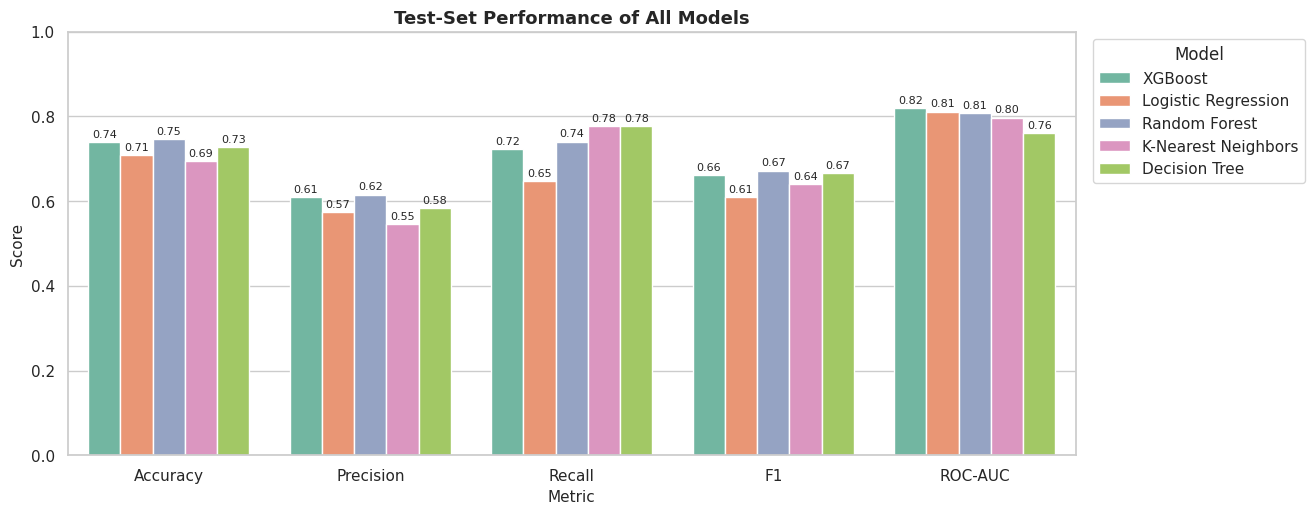

In [33]:
plot_df = model_comparison.melt(id_vars="Model", value_vars=main_metrics, var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(13, 5.5))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette="Set2", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
ax.set_title("Test-Set Performance of All Models")
ax.set_xlabel("Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.0)
ax.legend(title="Model", bbox_to_anchor=(1.01, 1), loc="upper left")
save_fig(fig, "12_model_comparison.png")
plt.show()

## 13. Confusion Matrices

A confusion matrix breaks the predictions down into four cells:

| | Predicted Negative | Predicted Positive |
|---|---|---|
| **Actual Negative** | **TN** – correctly predicted as no diabetes | **FP** – healthy patient flagged as diabetic (false alarm) |
| **Actual Positive** | **FN** – diabetic patient missed by the model | **TP** – diabetic patient correctly flagged |

**Why false negatives matter in screening.** In a screening workflow, a *false positive* usually leads to a follow-up confirmatory test, which costs time and money but would reveal the error. A *false negative* means a person who may have diabetes is told they are low-risk and may not be referred for testing, delaying care. For this reason, a screening-oriented model should keep FN low (high recall), while keeping FP at a manageable level. This is a general consideration for an academic model, not a clinical recommendation.

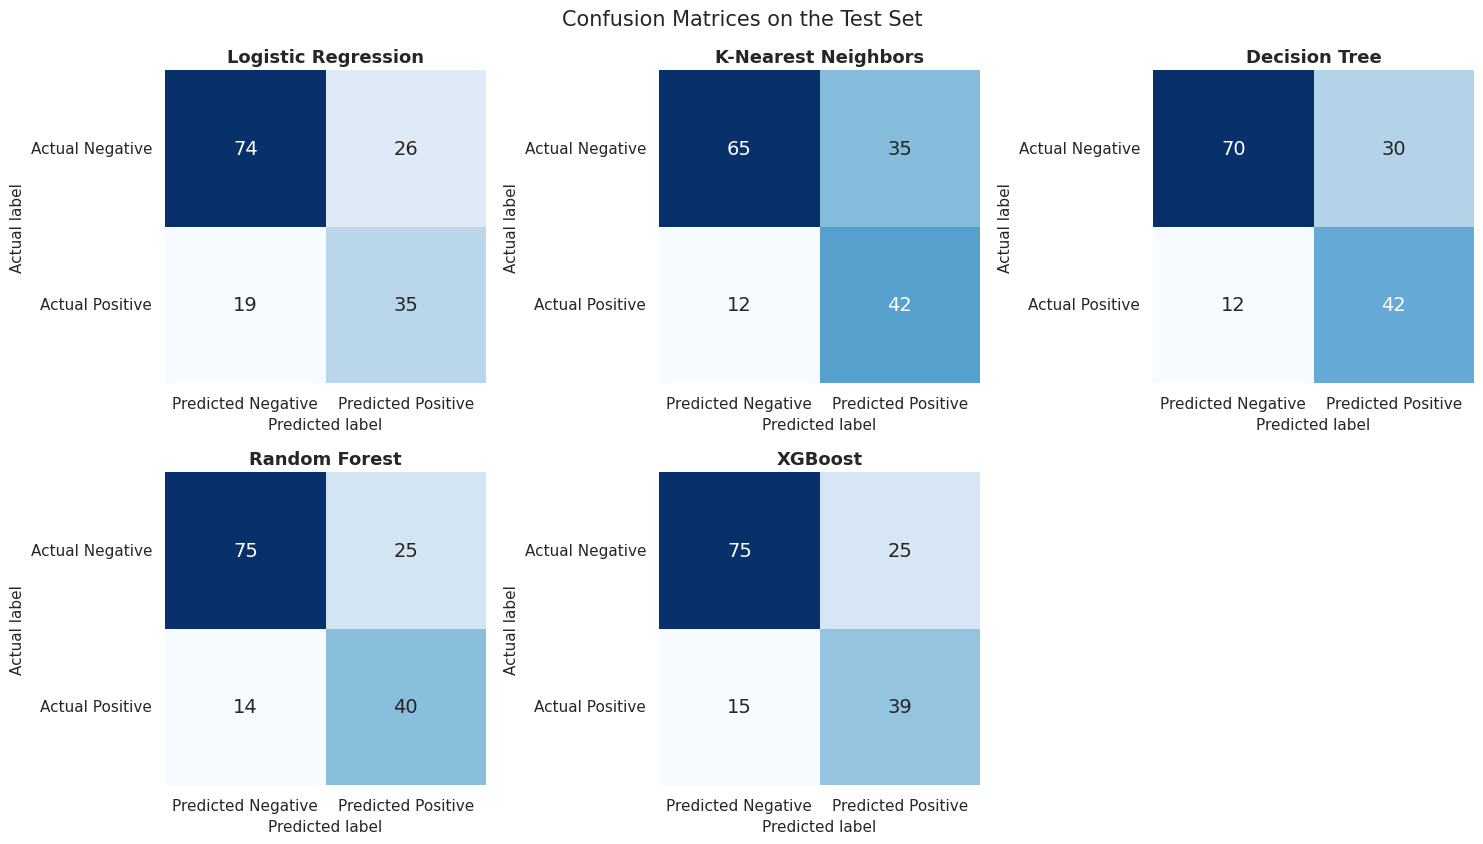

,Model,TP,TN,FP,FN,Recall,Specificity
0,XGBoost,39,75,25,15,0.722,0.75
1,Logistic Regression,35,74,26,19,0.648,0.74
2,Random Forest,40,75,25,14,0.741,0.75
3,K-Nearest Neighbors,42,65,35,12,0.778,0.65
4,Decision Tree,42,70,30,12,0.778,0.70


In [34]:
plot_confusion_matrices(models, X_test, y_test, save_path=FIG_DIR / "13_confusion_matrices.png")
results[["Model", "TP", "TN", "FP", "FN", "Recall", "Specificity"]].round(3)

**Reading the matrices.** The test set contains 54 diabetic and 100 non-diabetic patients. Decision Tree and KNN miss the fewest diabetic patients (12 FN each), but they also raise the most false alarms (30 and 35 FP). Random Forest and XGBoost miss 14 diabetic patients while producing fewer false alarms (25 and 24 FP). Logistic Regression misses the most diabetic patients (19 FN). This illustrates the **trade-off between recall and precision/specificity**: a model that flags more people catches more true cases but also produces more false positives.

## 14. ROC Curves

The **ROC curve** plots the true-positive rate (recall) against the false-positive rate as the decision threshold moves from 1 to 0. A model that ranks patients perfectly reaches the top-left corner; random guessing follows the diagonal.

**ROC-AUC** (area under the curve) can be read as: *the probability that the model gives a randomly chosen diabetic patient a higher risk score than a randomly chosen non-diabetic patient.* 0.5 = random, 1.0 = perfect ranking. Because it does not depend on a single threshold, ROC-AUC is a good overall measure of how well a model separates the two classes.

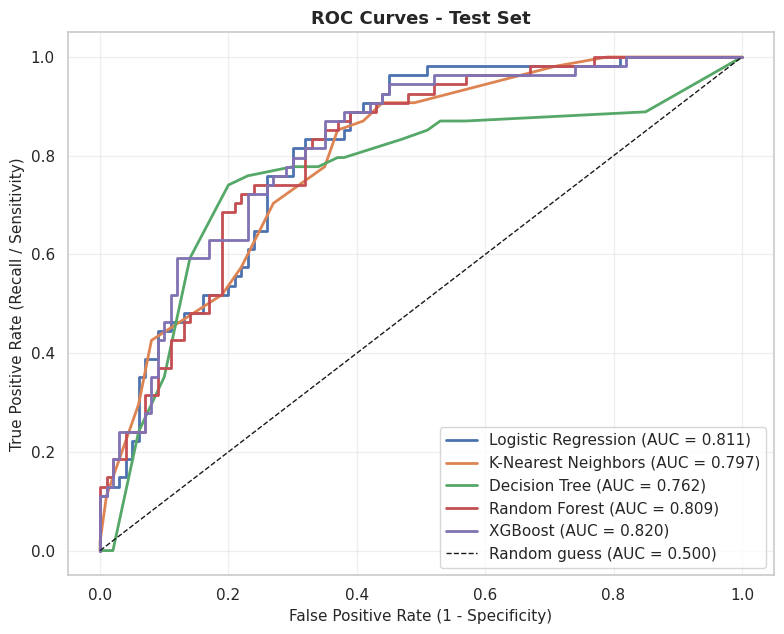

In [35]:
plot_roc_curves(models, X_test, y_test, save_path=FIG_DIR / "14_roc_curves.png")

All five models are far above the random baseline. XGBoost, Logistic Regression and Random Forest have very similar test AUCs (about 0.81–0.83) and nearly overlapping curves. The single Decision Tree has the lowest AUC, which is expected because one shallow tree produces only a few distinct probability values.

## 15. Model Comparison and Selection

First, which model is best on each individual metric (test set):

In [36]:
best_table = best_per_metric(results)
best_table

,Metric,Best model,Value
0,Accuracy,Random Forest,0.7468
1,Precision,Random Forest,0.6154
2,Recall,K-Nearest Neighbors,0.7778
3,F1,Random Forest,0.6723
4,ROC-AUC,XGBoost,0.8196


**No single model wins every metric**, so the final model should not be chosen on accuracy alone. Accuracy is especially misleading with imbalanced classes.

**Selection criteria.** The test set has only 154 patients, so one or two predictions can change a metric noticeably. To make a fair and stable choice:

1. **Screening requirement (recall).** Because missed diabetic cases are the costliest error in screening, a candidate must reach **recall ≥ 0.70 in both cross-validation and the test set**.
2. **Balanced overall performance.** Among the eligible models, choose the highest **overall score**: the mean of all five metrics (Accuracy, Precision, Recall, F1, ROC-AUC), averaged over **cross-validation (training data)** and the **hold-out test set**. Giving equal weight to the two evaluations rewards models that perform consistently instead of being lucky on one split.

No hyperparameters were changed based on the test set. The test set is used only to compare the five pre-defined pipelines.

In [37]:
cv_metric_map = {"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall", "F1": "f1", "ROC-AUC": "roc_auc"}
selection = pd.DataFrame({
    "Model": results["Model"],
    "Test mean (5 metrics)": results[main_metrics].mean(axis=1).values,
    "CV mean (5 metrics)": [cv_results.loc[m, [f"CV {v} mean" for v in cv_metric_map.values()]].mean()
                            for m in results["Model"]],
    "Test Recall": results["Recall"].values,
    "CV Recall": [cv_results.loc[m, "CV recall mean"] for m in results["Model"]],
})
selection["Overall score"] = selection[["Test mean (5 metrics)", "CV mean (5 metrics)"]].mean(axis=1)
selection["Recall >= 0.70 (CV & test)"] = (selection[["Test Recall", "CV Recall"]].min(axis=1) >= 0.70)
selection = selection.sort_values("Overall score", ascending=False).reset_index(drop=True)

eligible = selection[selection["Recall >= 0.70 (CV & test)"]]
FINAL_MODEL_NAME = (eligible if len(eligible) else selection).iloc[0]["Model"]
final_model = models[FINAL_MODEL_NAME]

print("Selected final model:", FINAL_MODEL_NAME)
selection.round(4)

Selected final model: Random Forest


,Model,Test mean (5 metrics),CV mean (5 metrics),Test Recall,CV Recall,Overall score,Recall >= 0.70 (CV & test)
0,Random Forest,0.7168,0.7396,0.7407,0.7195,0.7282,True
1,XGBoost,0.7105,0.7139,0.7222,0.6867,0.7122,False
2,K-Nearest Neighbors,0.6913,0.7196,0.7778,0.7898,0.7054,True
3,Logistic Regression,0.6699,0.7372,0.6481,0.7244,0.7036,False
4,Decision Tree,0.7033,0.6602,0.7778,0.6824,0.6818,False


**Result of the selection.**

* **Random Forest** has the highest overall score and meets the recall requirement in both cross-validation and the test set. It ranks first or second on most metrics in *both* evaluations, which makes it the most consistent model.
* **XGBoost** has the best test ROC-AUC, accuracy, precision and F1, but its cross-validated recall is below 0.70, so its strong test result is less consistent across folds.
* **Logistic Regression** has the best cross-validated ROC-AUC, but its test recall is the lowest of all models (it missed 19 of 54 diabetic patients).
* **KNN** and the **Decision Tree** achieve high recall, but with clearly lower precision and specificity, i.e. many false alarms.

**Random Forest is therefore chosen as the final model**: it balances high recall with good precision and ROC-AUC, and its performance is stable across cross-validation and the test set. The margins between the top models are small, and with a different random split their order could change. This uncertainty is discussed in the limitations.

## 16. Feature Importance (Interpretation)

Tree-based models give a built-in **impurity-based feature importance**: how much each feature reduces impurity (Gini / loss) across all splits, normalised to sum to 1. For comparison, the absolute standardised coefficients of Logistic Regression are also shown (comparable because all features were standardised).

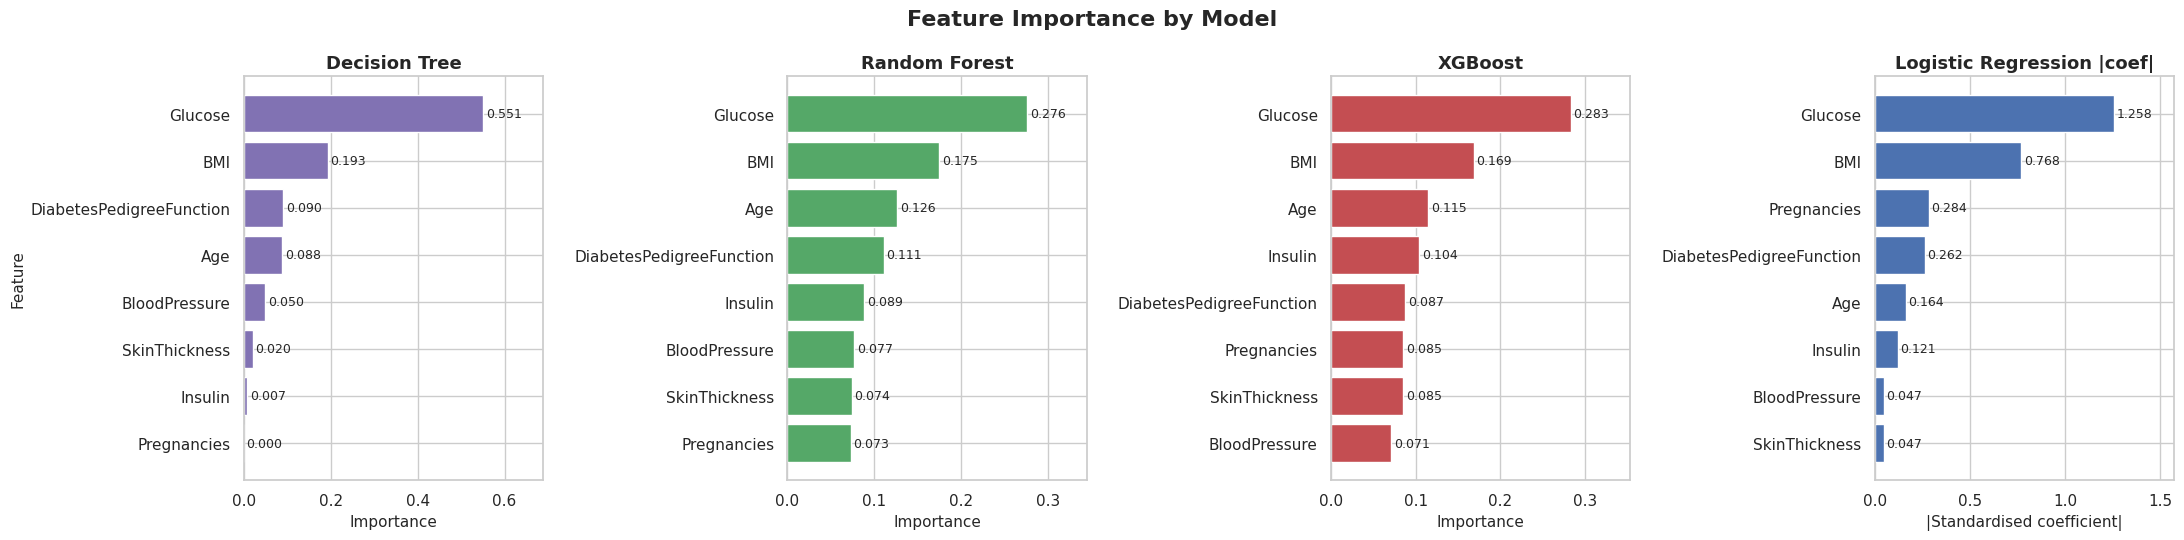

,Decision Tree,Random Forest,XGBoost,Logistic Regression |coef|
Glucose,0.551,0.276,0.283,1.258
BMI,0.193,0.175,0.169,0.768
Age,0.088,0.126,0.115,0.164
DiabetesPedigreeFunction,0.090,0.111,0.087,0.262
Insulin,0.007,0.089,0.104,0.121
BloodPressure,0.050,0.077,0.071,0.047
SkinThickness,0.020,0.074,0.085,0.047
Pregnancies,0.000,0.073,0.085,0.284


In [38]:
importance = pd.DataFrame({
    "Decision Tree": models["Decision Tree"].named_steps["model"].feature_importances_,
    "Random Forest": models["Random Forest"].named_steps["model"].feature_importances_,
    "XGBoost": models["XGBoost"].named_steps["model"].feature_importances_,
    "Logistic Regression |coef|": np.abs(models["Logistic Regression"].named_steps["model"].coef_[0]),
}, index=FEATURES)

fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
for ax, col, color in zip(axes, importance.columns, ["#8172B3", "#55A868", "#C44E52", "#4C72B0"]):
    s = importance[col].sort_values()
    bars = ax.barh(s.index, s.values, color=color)
    ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=9)
    ax.set_title(col)
    ax.set_xlabel("Importance" if "coef" not in col else "|Standardised coefficient|")
    ax.set_ylabel("Feature" if ax is axes[0] else "")
    ax.set_xlim(0, s.max() * 1.25)
fig.suptitle("Feature Importance by Model", fontsize=16, fontweight="bold")
fig.tight_layout()
save_fig(fig, "15_feature_importance.png")
plt.show()

importance.round(3).sort_values("Random Forest", ascending=False)

**Interpretation.** All four models agree that **Glucose is by far the most influential feature**. In the final Random Forest, it accounts for roughly a quarter of the total importance. **BMI** is consistently second. In the ensemble models, **Age**, **DiabetesPedigreeFunction** and **Insulin** form the next group, while **BloodPressure**, **SkinThickness** and **Pregnancies** contribute the least. Logistic Regression gives Pregnancies a somewhat larger weight. Pregnancies is correlated with Age, so the two features can share the same information. The agreement across very different algorithms makes this ranking more convincing.

Caveats: impurity-based importance can favour continuous features with many distinct values, and it is shared between correlated features (for example Glucose and Insulin). Importance reflects how much the *model relies on* a feature to make predictions. It does **not** prove that the feature causes diabetes.

## 17. SHAP Interpretation of the Final Model

**SHAP (SHapley Additive exPlanations)** explains an individual prediction by splitting the difference between the model's prediction and its average prediction into contributions from each feature, based on Shapley values from cooperative game theory.

* A **positive SHAP value** means the feature value pushed this patient's prediction **toward diabetes**.
* A **negative SHAP value** means it pushed the prediction **toward no diabetes**.
* The **mean absolute SHAP value** across patients measures a feature's overall (relative) importance.

SHAP values are computed for the final model on the 154 test patients. The model receives imputed and standardised features. To keep the plots readable, the colour scale uses the imputed values in their **original units**; scaling does not change which values are high or low. If SHAP fails (e.g. version incompatibility), the cell falls back to **permutation importance** so the notebook still completes.

In [39]:
final_clf = final_model.named_steps["model"]
X_test_imputed = pd.DataFrame(final_model.named_steps["imputer"].transform(X_test), columns=FEATURES)
X_test_model = pd.DataFrame(final_model.named_steps["scaler"].transform(X_test_imputed), columns=FEATURES)

SHAP_OK = False
try:
    import shap
    if hasattr(final_clf, "feature_importances_"):            # tree models
        explainer = shap.TreeExplainer(final_clf)
        sv = explainer.shap_values(X_test_model)
    else:                                                     # linear / other models
        background = shap.sample(X_test_model, 50, random_state=RANDOM_STATE)
        explainer = shap.Explainer(final_clf.predict_proba, background)
        sv = explainer(X_test_model).values
    # Normalise output shape to (n_samples, n_features) for the positive class
    if isinstance(sv, list):
        sv = sv[1]
    sv = np.asarray(sv)
    if sv.ndim == 3:
        sv = sv[:, :, 1]
    shap_values = sv
    SHAP_OK = True
    print(f"SHAP {shap.__version__}: computed values with shape {shap_values.shape} for {FINAL_MODEL_NAME}")
except Exception as exc:
    print("SHAP could not be computed, using permutation importance instead. Reason:", exc)

SHAP 0.52.0: computed values with shape (154, 8) for Random Forest


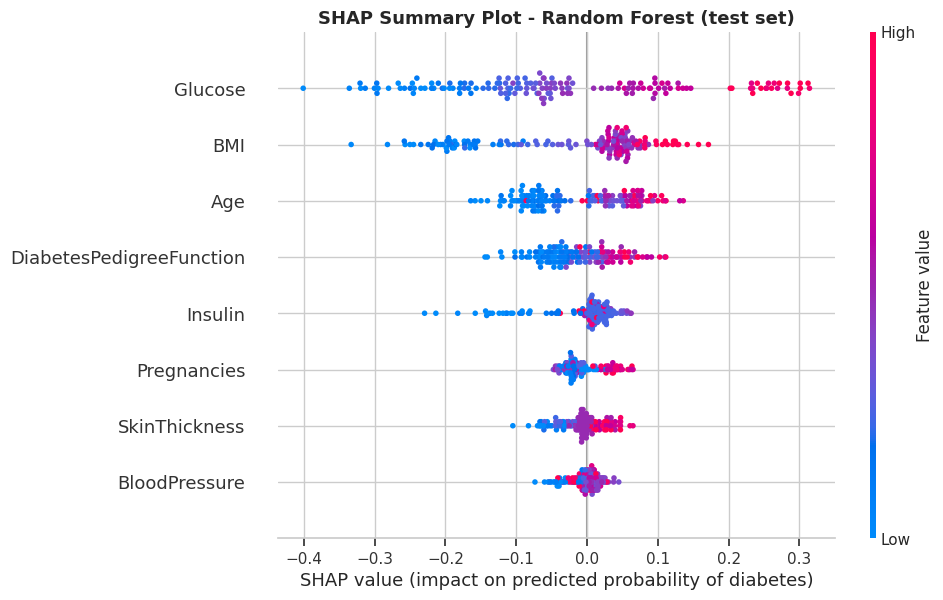

In [40]:
if SHAP_OK:
    shap.summary_plot(shap_values, X_test_imputed, feature_names=FEATURES, show=False, plot_size=(10, 6))
    fig = plt.gcf()
    plt.title(f"SHAP Summary Plot - {FINAL_MODEL_NAME} (test set)", fontsize=13, fontweight="bold")
    plt.xlabel("SHAP value (impact on predicted probability of diabetes)")
    save_fig(fig, "16_shap_summary.png")
    plt.show()
else:
    perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=20,
                                  random_state=RANDOM_STATE)
    s = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.barh(s.index, s.values, color="#55A868")
    ax.set_title(f"Permutation Importance (fallback) - {FINAL_MODEL_NAME}")
    ax.set_xlabel("Mean decrease in ROC-AUC when the feature is shuffled")
    ax.set_ylabel("Feature")
    save_fig(fig, "16_shap_summary.png")
    plt.show()

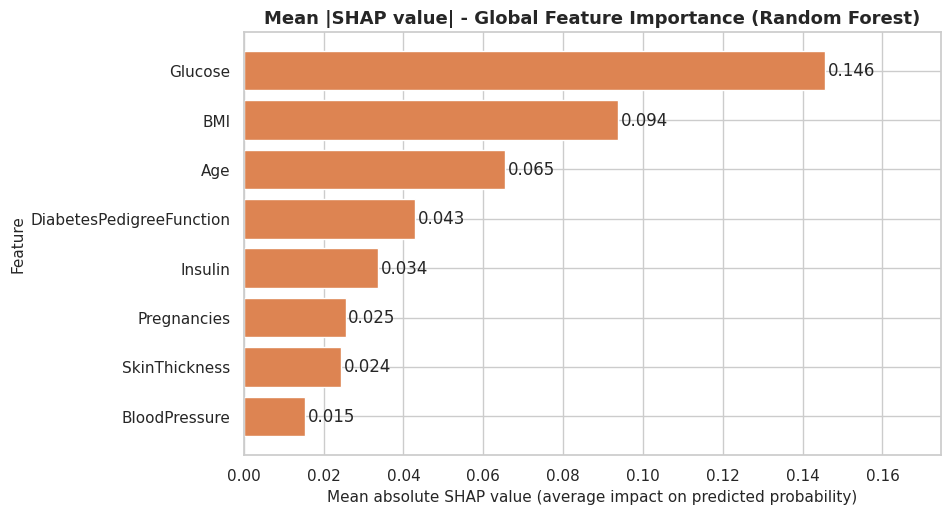

,Mean |SHAP|,"Corr(feature value, SHAP)",Higher value pushes prediction
Glucose,0.146,0.955,toward Diabetes
BMI,0.094,0.837,toward Diabetes
Age,0.065,0.735,toward Diabetes
DiabetesPedigreeFunction,0.043,0.682,toward Diabetes
Insulin,0.034,0.237,toward Diabetes
Pregnancies,0.025,0.635,toward Diabetes
SkinThickness,0.024,0.779,toward Diabetes
BloodPressure,0.015,0.254,toward Diabetes


In [41]:
if SHAP_OK:
    mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES).sort_values()
    fig, ax = plt.subplots(figsize=(9, 5.5))
    bars = ax.barh(mean_abs.index, mean_abs.values, color="#DD8452")
    ax.bar_label(bars, fmt="%.3f", padding=2)
    ax.set_title(f"Mean |SHAP value| - Global Feature Importance ({FINAL_MODEL_NAME})")
    ax.set_xlabel("Mean absolute SHAP value (average impact on predicted probability)")
    ax.set_ylabel("Feature")
    ax.set_xlim(0, mean_abs.max() * 1.2)
    save_fig(fig, "17_shap_importance_bar.png")
    plt.show()

    # Direction: does a higher feature value tend to push toward diabetes (+) or away (-)?
    direction = [np.corrcoef(X_test_imputed[f], shap_values[:, i])[0, 1] for i, f in enumerate(FEATURES)]
    shap_table = pd.DataFrame({"Mean |SHAP|": np.abs(shap_values).mean(axis=0),
                               "Corr(feature value, SHAP)": direction}, index=FEATURES)
    shap_table["Higher value pushes prediction"] = np.where(shap_table["Corr(feature value, SHAP)"] > 0,
                                                            "toward Diabetes", "toward No Diabetes")
    display(shap_table.sort_values("Mean |SHAP|", ascending=False).round(3))

**How to read the SHAP summary plot.** Each dot is one test patient. Its horizontal position is the SHAP value (how much that feature moved the predicted probability), and its colour is the feature value (red = high, blue = low).

**Interpretation for the final Random Forest**

* **Glucose** has the largest mean |SHAP| value. High glucose values (red) lie on the positive side and push predictions toward *diabetes*, while low values (blue) push toward *no diabetes*. This matches the EDA.
* **BMI** and **Age** come next. Higher BMI and older age are associated with higher predicted risk.
* **DiabetesPedigreeFunction**, **Pregnancies** and **SkinThickness** have smaller effects in the same direction: higher values tend to raise predicted risk.
* **Insulin** behaves asymmetrically. *Low* insulin values push predictions clearly toward no diabetes, while high values have only a small effect. Many Insulin values were imputed with the training median, which concentrates them near zero SHAP.
* **BloodPressure** has the smallest average impact and no clear direction (red and blue dots are mixed around zero).
* The SHAP ranking broadly agrees with the impurity-based importance in Section 16, which increases confidence in the interpretation.

**Caution.** SHAP explains *how this model uses the features*; it does not show that a feature *causes* diabetes. Correlated features (e.g. SkinThickness and BMI) can share or swap credit, and imputed values for Insulin and SkinThickness carry less information than measured values.

## 18. Final Model

The final model is the **Random Forest pipeline** (median imputation → standard scaling → SMOTE → Random Forest with 300 trees). Its performance on the held-out test set:

In [42]:
final_row = results.set_index("Model").loc[FINAL_MODEL_NAME]
final_cv = cv_results.loc[FINAL_MODEL_NAME]

print("=" * 62)
print(f"  FINAL MODEL: {FINAL_MODEL_NAME}")
print("=" * 62)
for m in main_metrics + ["Specificity"]:
    print(f"  {m:<12} (test) : {final_row[m]:.4f}")
print("-" * 62)
print(f"  Cross-validated ROC-AUC (train): {final_cv['CV roc_auc mean']:.4f} ± {final_cv['CV roc_auc std']:.4f}")
print(f"  Cross-validated Recall  (train): {final_cv['CV recall mean']:.4f} ± {final_cv['CV recall std']:.4f}")
print(f"  Confusion matrix (test): TP={int(final_row['TP'])}  TN={int(final_row['TN'])}  FP={int(final_row['FP'])}  FN={int(final_row['FN'])}")
print("=" * 62)

  FINAL MODEL: Random Forest
  Accuracy     (test) : 0.7468
  Precision    (test) : 0.6154
  Recall       (test) : 0.7407
  F1           (test) : 0.6723
  ROC-AUC      (test) : 0.8087
  Specificity  (test) : 0.7500
--------------------------------------------------------------
  Cross-validated ROC-AUC (train): 0.8291 ± 0.0252
  Cross-validated Recall  (train): 0.7195 ± 0.0269
  Confusion matrix (test): TP=40  TN=75  FP=25  FN=14


**Why Random Forest?**

* It caught **40 of the 54 diabetic patients** in the test set (recall ≈ 0.74) while keeping precision ≈ 0.62 and specificity ≈ 0.75.
* Its test ROC-AUC (≈ 0.81) and cross-validated ROC-AUC (≈ 0.83) are close, showing **stable** behaviour rather than a lucky split.
* It had the best overall score under the predefined, recall-aware selection rule.
* As an ensemble of trees, it captures non-linear relationships and is less prone to overfitting than a single Decision Tree. Its feature importance and SHAP values are easy to explain.

## 19. Sample Prediction

`predict_diabetes()` takes the eight measurements for one patient, applies the same cleaning rule (a 0 in Glucose, BloodPressure, SkinThickness, Insulin or BMI is treated as "not measured"), and passes them through the fitted final pipeline. It returns the predicted class and the model's estimated probability of diabetes.

> **Important:** this is an **academic machine-learning demonstration, not a medical diagnosis.** The probability is a model output learned from one historical dataset and is not clinically validated.

In [43]:
def predict_diabetes(Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI,
                     DiabetesPedigreeFunction, Age, model=None, threshold=0.5, verbose=True):
    """Predict diabetes onset for one patient (academic demonstration only).

    Returns a dict with the predicted class (0/1), a readable label and the
    predicted probability of diabetes.
    """
    model = final_model if model is None else model
    values = dict(Pregnancies=Pregnancies, Glucose=Glucose, BloodPressure=BloodPressure,
                  SkinThickness=SkinThickness, Insulin=Insulin, BMI=BMI,
                  DiabetesPedigreeFunction=DiabetesPedigreeFunction, Age=Age)
    if any(v is not None and v < 0 for v in values.values()):
        raise ValueError("Measurements cannot be negative.")
    patient = replace_invalid_zeros(pd.DataFrame([values], columns=FEATURES).astype(float))

    probability = float(model.predict_proba(patient)[0, 1])
    predicted_class = int(probability >= threshold)
    label = "Diabetes likely" if predicted_class == 1 else "Diabetes unlikely"
    if verbose:
        print(f"Predicted class: {label} ({predicted_class})")
        print(f"Probability of diabetes: {probability:.1%}")
        print("Note: academic ML demonstration - NOT a medical diagnosis.")
    return {"predicted_class": predicted_class, "label": label, "probability": probability}


print("Example patient A (high glucose and BMI, older):")
result_a = predict_diabetes(Pregnancies=6, Glucose=168, BloodPressure=74, SkinThickness=35, Insulin=200,
                            BMI=38.2, DiabetesPedigreeFunction=0.85, Age=50)
print("\nExample patient B (normal glucose and BMI, younger):")
result_b = predict_diabetes(Pregnancies=1, Glucose=89, BloodPressure=66, SkinThickness=23, Insulin=94,
                            BMI=24.5, DiabetesPedigreeFunction=0.25, Age=24)
print("\nExample patient C (Insulin and SkinThickness not measured -> recorded as 0):")
result_c = predict_diabetes(Pregnancies=3, Glucose=130, BloodPressure=70, SkinThickness=0, Insulin=0,
                            BMI=32.0, DiabetesPedigreeFunction=0.45, Age=35)

Example patient A (high glucose and BMI, older):
Predicted class: Diabetes likely (1)
Probability of diabetes: 87.2%
Note: academic ML demonstration - NOT a medical diagnosis.

Example patient B (normal glucose and BMI, younger):
Predicted class: Diabetes unlikely (0)
Probability of diabetes: 1.7%
Note: academic ML demonstration - NOT a medical diagnosis.

Example patient C (Insulin and SkinThickness not measured -> recorded as 0):
Predicted class: Diabetes likely (1)
Probability of diabetes: 66.7%
Note: academic ML demonstration - NOT a medical diagnosis.


In [44]:
# Sanity check on five real test patients (NaN = value was recorded as 0, i.e. not measured).
# The raw rows (with their original zeros) are passed to predict_diabetes().
check = X_test.head(5).copy()
check["Actual"] = y_test.head(5).map(OUTCOME_LABELS).values
check["P(diabetes)"] = [predict_diabetes(**row, verbose=False)["probability"]
                        for row in df_raw.loc[X_test.head(5).index, FEATURES].to_dict("records")]
check["Prediction"] = np.where(check["P(diabetes)"] >= 0.5, "Diabetes likely", "Diabetes unlikely")
check.round(3)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Actual,P(diabetes),Prediction
44,7,159.0,64.0,NaN,NaN,27.4,0.294,40,No Diabetes,0.783,Diabetes likely
672,10,68.0,106.0,23.0,49.0,35.5,0.285,47,No Diabetes,0.186,Diabetes unlikely
700,2,122.0,76.0,27.0,200.0,35.9,0.483,26,No Diabetes,0.223,Diabetes unlikely
630,7,114.0,64.0,NaN,NaN,27.4,0.732,34,Diabetes,0.403,Diabetes unlikely
81,2,74.0,NaN,NaN,NaN,NaN,0.102,22,No Diabetes,0.134,Diabetes unlikely


## 20. Limitations

* **Small dataset.** 768 patients (154 in the test set) is small. Metrics computed on 154 patients have wide uncertainty: one patient changes test recall by almost 2 percentage points.
* **Narrow demographics.** All patients are Pima Indian women aged 21 or older. The model may not generalise to men, other ethnic groups or younger people.
* **Historical data.** The data were collected decades ago, using diagnostic criteria and measurement practices of that time.
* **Potential sampling bias.** The cohort comes from a specific population study and is not a random sample of any general population.
* **Measurement quality and missing values.** Nearly half of Insulin values and about 30 % of SkinThickness values were missing (recorded as 0). Median imputation fills these gaps but cannot recover the lost information, and it reduces the variability of these features.
* **Class imbalance.** SMOTE creates *synthetic* patients by interpolation. These are plausible but not real observations.
* **Model generalisation and selection.** No extensive hyperparameter tuning was done, and the final model was chosen among five candidates using CV and test results. With a different random split, the ranking of closely matched models could change.
* **No external validation.** The model has not been tested on data from another hospital, population or time period.
* **Fixed threshold.** A 0.5 probability threshold was used. A real screening tool would choose its threshold based on the costs of FN and FP errors, and would need calibrated probabilities.
* **Prediction ≠ diagnosis.** The model finds statistical associations. It is not a clinical diagnostic test, and its feature importances are not causal effects.

## 21. Conclusion

* **Problem.** We built a supervised binary classifier to predict diabetes onset (Outcome 0/1) from eight routine diagnostic measurements, as an academic example of a screening-support model.
* **Dataset.** Pima Indians Diabetes Dataset: 768 patients, 8 features, 35 % diabetic.
* **Preprocessing.** Physiologically impossible zeros in five features were treated as missing. Data were split 80/20 with stratification *before* any fitting. Median imputation, standard scaling and SMOTE were learned from training data only, inside one `imblearn` pipeline, so there is no leakage.
* **Models compared.** Logistic Regression, K-Nearest Neighbors, Decision Tree, Random Forest and XGBoost, evaluated with 5-fold cross-validation on the training set and on the hold-out test set.
* **Best model.** **Random Forest**, selected using a recall-aware, multi-metric rule. Test results: accuracy 0.747, precision 0.615, recall 0.741, F1 0.672, ROC-AUC 0.809 (cross-validated ROC-AUC 0.829).
* **Important features.** Glucose is clearly the most influential predictor, followed by BMI, Age and DiabetesPedigreeFunction. Feature importance, SHAP, logistic-regression coefficients and EDA correlations all agree on this.
* **Main findings.** All models clearly beat random guessing (AUC 0.76–0.83). Ensemble methods (Random Forest, XGBoost) and Logistic Regression performed similarly well, which suggests the signal in this dataset is fairly simple and dominated by glucose. Handling class imbalance substantially improved recall at a small cost in accuracy.
* **Future improvements.** Larger and more diverse data, external validation, cross-validated hyperparameter tuning, probability calibration and threshold optimisation (see below).

## 22. Future Scope

1. **Larger and more diverse datasets.** Include men, different ethnicities and age groups, and more recent data (e.g. national health surveys).
2. **External validation.** Test the model on data from a different hospital or population before drawing any practical conclusion.
3. **Hyperparameter optimisation.** Use `GridSearchCV` / `RandomizedSearchCV` or nested cross-validation on training data only.
4. **Explainable AI.** Show per-patient SHAP explanations (waterfall plots) so a clinician can see *why* a patient was flagged.
5. **Probability calibration.** Use Platt scaling or isotonic regression so that a predicted "70 %" truly corresponds to about a 70 % observed rate.
6. **Threshold selection.** Choose a decision threshold that reflects the relative costs of false negatives and false positives.
7. **Additional clinical features.** HbA1c, family history details, physical activity and diet could improve predictions.
8. **Deployment as a screening-support tool.** A simple web form backed by the saved pipeline, used only to support (not replace) clinical judgement.
9. **Monitoring model drift.** After deployment, track input distributions and performance over time and retrain when they change.

## 23. Final KDD Mapping

| KDD Stage | Implementation in Project | Notebook section |
|---|---|---|
| Problem Definition | Diabetes onset prediction as binary classification (Outcome 0/1) | 1 |
| Data Selection | Pima Indians Diabetes Dataset (768 × 9) | 4 |
| Data Understanding | Shape, types, summary statistics, duplicates, class balance | 5 |
| Data Cleaning | Invalid zeros in Glucose, BloodPressure, SkinThickness, Insulin, BMI → NaN | 6 |
| Data Transformation | Stratified split, then median imputation + standard scaling (fit on train only) + SMOTE | 8–9 |
| EDA | Distributions, by-outcome histograms, boxplots, correlation heatmap, pairplot | 7 |
| Modeling | Logistic Regression, KNN, Decision Tree, Random Forest, XGBoost in leak-free pipelines | 10–11 |
| Evaluation | Accuracy, Precision, Recall, F1, ROC-AUC, confusion matrices, ROC curves, 5-fold CV | 12–15 |
| Interpretation | Feature importance + SHAP | 16–17 |
| Knowledge Discovery | Glucose, BMI and Age are the strongest predictive patterns; Random Forest selected as a balanced screening model | 18–21 |

In [45]:
generated = sorted(p.name for p in FIG_DIR.glob("*.png"))
print(f"{len(generated)} figures saved in results/figures/:")
for name in generated:
    print("  -", name)
print("\nResult files:", [p.name for p in sorted(RESULTS_DIR.glob("*.csv"))])

17 figures saved in results/figures/:
  - 01_kdd_workflow.png
  - 02_invalid_zeros.png
  - 03_outcome_distribution.png
  - 04_feature_distributions.png
  - 05_glucose_by_outcome.png
  - 06_bmi_by_outcome.png
  - 07_age_by_outcome.png
  - 08_boxplots_by_outcome.png
  - 09_correlation_heatmap.png
  - 10_pairplot_selected_features.png
  - 11_smote_class_distribution.png
  - 12_model_comparison.png
  - 13_confusion_matrices.png
  - 14_roc_curves.png
  - 15_feature_importance.png
  - 16_shap_summary.png
  - 17_shap_importance_bar.png

Result files: ['metrics.csv', 'model_comparison.csv']
